# Backtesting Two Development Patterns on the Next Diagonal

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

A change in how a company handles claims can push whole diagonals of link
ratios up or down. {doc}`ValuationCorrelation <plot_valuation_correlation>`
tests for that kind of calendar-year effect. Once a test flags one, the
actuary has to choose between a pattern averaged over all diagonals and a
pattern from the recent diagonals only.

This example treats the two patterns as a parameter grid. Each pattern goes
into `DevelopmentConstant`, `GridSearch` fits both, and a scorer compares
each projection with the next diagonal, which the fitted triangle has not
seen. The {doc}`Chapter 15 monitoring notebook <../friedland/chapter_15_monitoring>`
makes the same comparison of projected and actual development for a single
selected pattern.

The data are the commercial auto triangles of State Farm Mut Grp in
`clrd2025`. The fitted triangle stops at the 2007 diagonal, and the 2008
diagonal serves as the test. Valuations in the sample sit at 23:59:59 on
December 31, so the filter `valuation < "2008"` keeps the 2007 diagonal.

In [2]:
full = cl.load_sample("clrd2025").loc["State Farm Mut Grp", "comauto"]
tri = full[full.valuation < "2008"]
tri["IncurredLosses"]

,12,24,36,48,60,72,84,96,108,120
1998,"139,047","140,490","147,785","151,858","154,989","156,396","156,903","157,870","158,584","158,446"
1999,"134,725","144,002","151,640","155,435","156,787","157,243","158,179","159,058","159,334",
2000,"139,275","153,675","161,654","168,684","171,068","173,890","175,689","175,508",,
2001,"140,194","146,159","145,503","147,129","150,249","152,184","151,727",,,
2002,"158,856","160,571","164,819","174,470","177,425","178,957",,,,
2003,"153,638","161,267","169,677","180,888","183,939",,,,,
2004,"145,570","161,958","172,548","177,466",,,,,,
2005,"159,494","182,822","206,850",,,,,,,
2006,"174,143","190,583",,,,,,,,
2007,"181,760",,,,,,,,,


## The incurred diagonals move and the paid diagonals do not

The per-diagonal test at `p_critical=0.05` flags three incurred diagonals
and no paid diagonal:

In [3]:
columns = {"Incurred": "IncurredLosses", "Paid": "CumPaidLoss"}
flags = pd.DataFrame({
    name: cl
    .ValuationCorrelation(tri[col], p_critical=0.05, total=False)
    .z_critical.to_frame(origin_as_datetime=False)
    .iloc[0]
    for name, col in columns.items()
})
flags.index = [str(v)[:4] for v in flags.index]
flags.rename_axis("Diagonal")

,Incurred,Paid
Diagonal,,
1999,False,False
2000,False,False
2001,False,False
2002,False,False
2003,False,False
2004,True,False
2005,True,False
2006,True,False
2007,False,False


The test over all diagonals together gives the same answer:

In [4]:
pd.Series(
    {
        name: bool(
            cl.ValuationCorrelation(
                tri[col], p_critical=0.05, total=True
            ).z_critical.values.flatten()[0]
        )
        for name, col in columns.items()
    },
    name="Flagged by the total test",
)

Incurred     True
Paid        False
Name: Flagged by the total test, dtype: bool

The next cell counts, for each incurred diagonal, the link ratios above and
below the median of their development age:

In [5]:
ratios = tri["IncurredLosses"].link_ratio.to_frame(origin_as_datetime=False)
signs = np.sign(ratios - ratios.median())
first = int(str(ratios.index[0])[:4])
year = first + np.add.outer(np.arange(ratios.shape[0]), np.arange(ratios.shape[1])) + 1
marks = pd.DataFrame({
    "year": year.flatten(),
    "sign": signs.to_numpy().flatten(),
}).dropna()
counts = pd.crosstab(marks["year"], marks["sign"]).rename(
    columns={-1.0: "Below median", 0.0: "At median", 1.0: "Above median"}
)
counts.loc[2002:2007]

sign,Below median,At median,Above median
year,,,
2002,3,0,1
2003,3,1,1
2004,6,0,0
2005,0,0,7
2006,0,1,7
2007,5,2,2


All 6 incurred link ratios that end in 2004 sit below their age's median.
In 2005 all 7 sit above it, and in 2006 7 of 8 do. Incurred development
slows for one year and then speeds up for two, while paid development shows
no flagged diagonal. That pattern fits a change in case reserving around
2005, but the data cannot say what State Farm changed.

## Two patterns as a parameter grid

`pattern` returns the age-to-age factors of a fitted `Development` as a
dictionary keyed by age, the form `DevelopmentConstant` takes. One pattern
averages all diagonals, `n_periods=-1`, and the other uses the latest 3.
The recent incurred pattern runs higher at the early ages:

In [6]:
def pattern(triangle, n_periods):
    dev = cl.Development(n_periods=n_periods).fit(triangle)
    ages = [int(str(a).split("-")[0]) for a in dev.ldf_.development]
    return dict(zip(ages, dev.ldf_.values[0, 0, 0, :].tolist()))


patterns = {
    "All diagonals": pattern(tri["IncurredLosses"], -1),
    "Latest 3": pattern(tri["IncurredLosses"], 3),
}
ldfs = pd.DataFrame(patterns).rename_axis("Age")
ldfs["Ratio"] = ldfs["Latest 3"] / ldfs["All diagonals"]
ldfs.round(4)

,All diagonals,Latest 3,Ratio
Age,,,
12,1.0718,1.1172,1.0423
24,1.0556,1.0850,1.0279
36,1.0380,1.0508,1.0124
48,1.0163,1.0182,1.0018
60,1.0101,1.0126,1.0025
72,1.0044,1.0047,1.0004
84,1.0034,1.0034,1.0000
96,1.0031,1.0031,1.0000
108,0.9991,0.9991,1.0000


The scorer reads the projected 2008 diagonal from `full_triangle_` and
subtracts the reported 2008 diagonal for accident years 1999 to 2007. The
grid runs once for incurred and once for paid, with patterns from the same
triangle, so paid serves as a control.

In [7]:
def diagonal_2008(triangle):
    by_valuation = triangle.dev_to_val().to_frame(origin_as_datetime=False)
    column = next(c for c in by_valuation.columns if str(c)[:4] == "2008")
    return by_valuation[column].dropna()


pipe = cl.Pipeline([
    ("dev", cl.DevelopmentConstant(style="ldf")),
    ("cl", cl.Chainladder()),
])
rows = []
for name, col in columns.items():
    reported = diagonal_2008(full[col])

    def error_2008(model, reported=reported):
        projected = diagonal_2008(model.named_steps.cl.full_triangle_)
        return float((projected - reported).loc[reported.index].sum())

    grid = cl.GridSearch(
        pipe,
        {"dev__patterns": [pattern(tri[col], -1), pattern(tri[col], 3)]},
        scoring={"error": error_2008},
        n_jobs=1,
    ).fit(tri[col])
    for label, error in zip(patterns, grid.results_["error"]):
        rows.append({
            "Column": name,
            "Pattern": label,
            "Reported 2008": float(reported.sum()),
            "Projected minus reported": error,
            "Error %": 100 * error / float(reported.sum()),
        })
results = pd.DataFrame(rows).set_index(["Column", "Pattern"])
results.round({"Reported 2008": 0, "Projected minus reported": 0, "Error %": 2})

Reported 2008  Projected minus reported  Error %
Column   Pattern                                                        
Incurred All diagonals      1678782.0                  -34700.0    -2.07
         Latest 3           1678782.0                  -17326.0    -1.03
Paid     All diagonals      1508361.0                  -12186.0    -0.81
         Latest 3           1508361.0                   -4464.0    -0.30

Both patterns project less than State Farm reported in 2008. On incurred
the all-diagonals pattern misses by 34,700 and the latest 3 miss by 17,326,
so the recent pattern halves the miss. On paid the miss falls from 12,186
to 4,464.

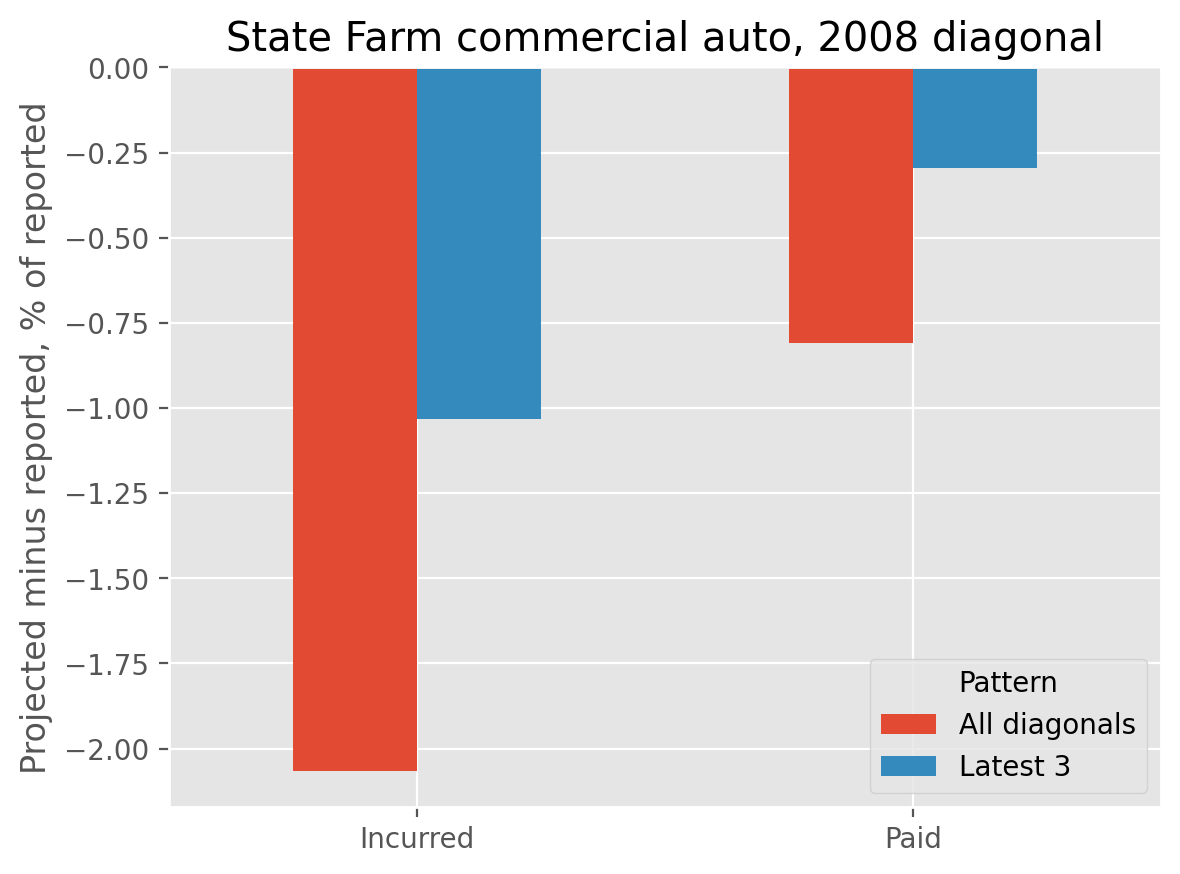

In [8]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

ax = (
    results["Error %"]
    .unstack("Pattern")
    .loc[["Incurred", "Paid"]]
    .plot(
        kind="bar",
        rot=0,
        title="State Farm commercial auto, 2008 diagonal",
        ylabel="Projected minus reported, % of reported",
        xlabel="",
    )
)
ax.axhline(0, color="grey", linewidth=1);

## What the backtest shows

The recent pattern does better on both columns, so part of the gain on
incurred reflects a shift that paid shares and not only the incurred
diagonals the test flagged. Several limits apply:

* This triangle came from a scan of many companies and lines for flagged
  diagonals, and the {doc}`calendar year example <plot_valuation_correlation>`
  shows how often per-diagonal flags appear by chance.
* Each flagged diagonal holds only 6 to 8 link ratios.
* One held-out diagonal is a single test. The sample runs to the 2016
  diagonal, so scoring later diagonals the same way would show whether the
  recent pattern keeps its lead.
* The data show when incurred development changed, not why.

The grid takes any number of patterns. A selected pattern from judgment or
an industry benchmark can join the two fitted ones as a third entry in
`dev__patterns`.